In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv(r"C:\Users\delam\OneDrive\Ironhack\Labs Boot camp\lab-eda-univariate\amazon_reino_unido\amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

Parte 1: Comprender las categorías de productos
Pregunta comercial : ¿Cuáles son las categorías de productos más populares en Amazon Reino Unido y cómo se comparan en términos de frecuencia de publicación?

1. Tablas de frecuencia :

Genere una tabla de frecuencias para el producto category.
¿Cuáles son las 5 categorías de productos más listadas?

2. Visualizaciones :

Muestra la distribución de productos en diferentes categorías mediante un gráfico de barras. Si tienes problemas para interpretar el gráfico, empieza por mostrar solo un subconjunto de las categorías principales.
Para un subconjunto de las categorías principales, visualiza sus proporciones mediante un gráfico circular. ¿Alguna categoría domina la lista?

In [ ]:
# Tablas de frecuencia

# Frequency table for 'category'
freq_table = df['category'].value_counts()

# Calculating the proportion of each unique value in the 'category'
prop_table = df['category'].value_counts(normalize=True)

freq_table, prop_table

# Las 5 categorías de productos más listadas son:
# Sports & Outdoors , Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body,  Birthday Gifts. 

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Motorbike Chassis                            107
 Alexa Built-In Devices                       107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Motorbike Chassis                         0.000044
 Alexa Built-In Devices  

In [7]:
my_table = pd.crosstab(index = df["category"],  # Make a crosstab
                              columns="count")      # Name the count column
my_table

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


C:\Users\delam\AppData\Local\Temp\ipykernel_27436\3813500440.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=my_table.index, y=my_table["count"], palette="Set3");


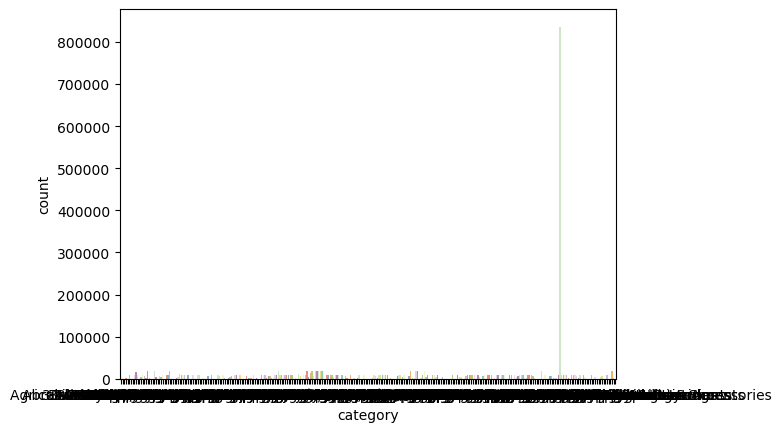

In [8]:
sns.barplot(x=my_table.index, y=my_table["count"], palette="Set3");

plt.show()

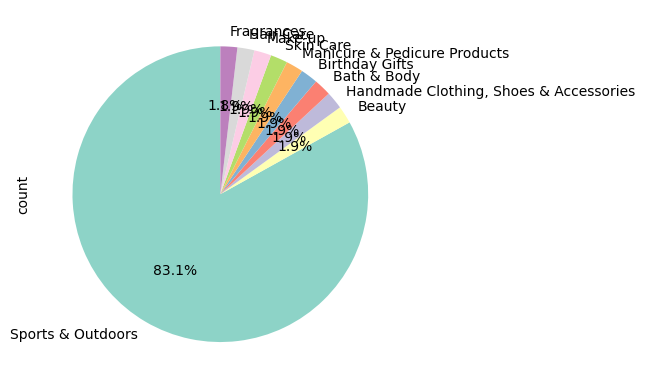

In [21]:
top_freq = freq_table.head(10)

top_freq.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

plt.show()

# claramente la categoría sports & outdoors domina con mucha superioridad el listado de categorías

Parte 2: Profundizando en la fijación de precios de los productos
Pregunta comercial : ¿Cómo se fijan los precios de los productos en Amazon Reino Unido? ¿Existen precios o rangos específicos que sean más comunes?

1. Medidas de centralidad :

Calcula la media, la mediana y la moda para los priceproductos.
¿Cuál es el precio promedio de los productos listados? ¿Cómo se compara esto con el precio más común (moda)?

2. Medidas de dispersión :

Determine la varianza, la desviación estándar, el rango y el rango intercuartílico del producto price.
¿Qué tan variados son los precios de los productos? ¿Existen indicadores de una diferencia significativa en los precios?

3. Visualizaciones :

¿Existe un rango de precios específico donde se ubica la mayoría de los productos? Crea un histograma para visualizar la distribución de los precios. Si te resulta difícil interpretar estos diagramas, reflexiona sobre el motivo y explica cómo podría solucionarse .
¿Existen productos con precios significativamente más altos que el resto? Utilice un diagrama de caja para mostrar la dispersión y los posibles valores atípicos en los precios de los productos.

In [24]:
# medidas de centralidad ('price')

mean = df['price'].mean().round(2)
median = df['price'].median()
mode = df['price'].mode()[0]

print('mean:', mean)
print('median:', median)
print('mode:', mode)

# El precio promedio de los productos listados es 89.24, lo cual es un precio mucho mayor al precio más común que es 9.99 (moda)

mean: 89.24
median: 19.09
mode: 9.99


In [28]:
# Medidas de dispersión

variance = round(df['price'].var(),2)
std_dev = round(df['price'].std(), 2)
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

print('var:', variance)
print('std_dev:', std_dev)
print('range:', range_price)
print('min:', min_price)
print('max:', max_price)
print('quant:', quantiles_price)

# Los precios de los productos varían de forma normal, el 75%  de los productos están entre 0 y 45.99, pero claramente hay una diferencia muy significativa en el último quadril
# donde se llega hasta el precio máximo de 100000

var: 119445.49
std_dev: 345.61
range: 100000.0
min: 0.0
max: 100000.0
quant: 0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64


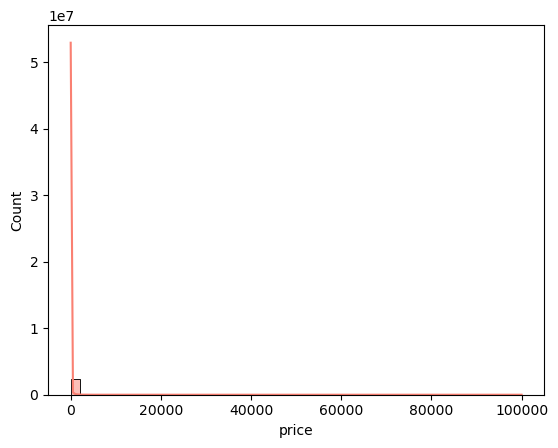

In [ ]:
# visualizaciones

# Histograma

sns.histplot(df['price'], kde=True, bins=50, color="salmon")

plt.show()

# Si existe un rango específico donde se ubican la mayoría de los productos, el 75% de estos están en el rango de 0 a 45.99, pero en el 25% de productos más costosos 
# este rango está entre 45.99 y 100000, lo cual es una diferencia muy grande, esto es lo que hace que el histograma sea tan difícil de interpretar, pues a simple vista no
# se logra ver nada, esto podría solucionarse haciendo un subconjunto con los productos del 25% superior y analizar por aparte las dos partes.
# Con el diagrama de caja se ve claramente esos productos outliers que están muy por encima del rango mayoritario.

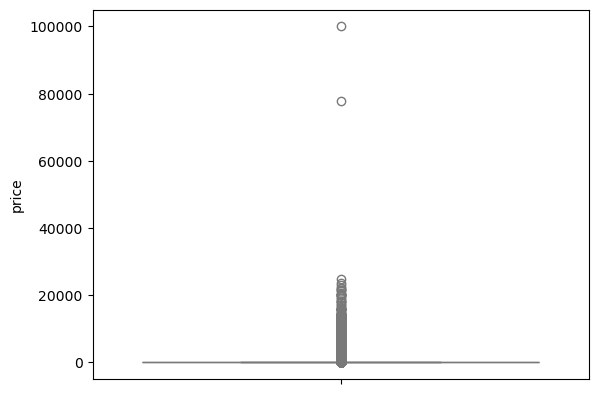

In [19]:
# Box plot

sns.boxplot(data = df['price'], color="lightblue")

plt.show()

Parte 3: Desglosando las calificaciones de los productos
Pregunta comercial : ¿Cómo califican los clientes los productos en Amazon Reino Unido, y existen patrones o tendencias en las calificaciones?

1. Medidas de centralidad :

Calcula la media, la mediana y la moda para los ratingproductos.
¿Cómo suelen valorar los clientes los productos? ¿Existe alguna tendencia común?

2. Medidas de dispersión :

Determine la varianza, la desviación estándar y el rango intercuartílico del producto rating.
¿Las valoraciones son coherentes o existe una gran variación en las opiniones de los clientes?

3. Forma de la distribución :

Calcule la asimetría y la curtosis de la ratingcolumna.
¿Las calificaciones se distribuyen normalmente o tienden hacia valores más altos o más bajos?

4. Visualizaciones :

Crea un histograma para visualizar la distribución de las valoraciones del producto. ¿Hay alguna valoración específica que sea más común?


In [ ]:
# medidas de centralidad ('stars')

mean = df['stars'].mean().round(2)
median = df['stars'].median()
mode = df['stars'].mode()[0]

print('mean:', mean)
print('median:', median)
print('mode:', mode)

# Los clientes valoran muy mal los productos con una calificación de 0, la tendencia en común es esta misma, una calificación de 0.

mean: 2.15
median: 0.0
mode: 0.0


In [ ]:
# Medidas de dispersión

variance = round(df['stars'].var(),2)
std_dev = round(df['stars'].std(), 2)
min_price = df['stars'].min()
max_price = df['stars'].max()
range_price = max_price - min_price
quantiles_price = df['stars'].quantile([0.25, 0.5, 0.75])

print('var:', variance)
print('std_dev:', std_dev)
print('range:', range_price)
print('min:', min_price)
print('max:', max_price)
print('quant:', quantiles_price)

# Exiate una gran diferencia en las valoraciones de los clientes, una gran mayoría califica con 0 sus productos, mientras un 25% los califica muy bien, con puntuaciones entre 4.4 y 5.

var: 4.82
std_dev: 2.19
range: 5.0
min: 0.0
max: 5.0
quant: 0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64


In [ ]:
# Forma de distribución (`stars`)

skewness_rating = df['stars'].skew().round(2)
kurtosis_rating = df['stars'].kurtosis().round(2)

print('skewnee:', skewness_rating)
print('kurtosis:', kurtosis_rating)

# Un valor de asimetría tan bajo, casi 0, daría una curva casi simétrica, con una ligera desviación a la derecha.
# La curtosis negativa en casi 2, plantea una distribución es más aplanada y dispersa de los datos

skewnee: 0.08
kurtosis: -1.93


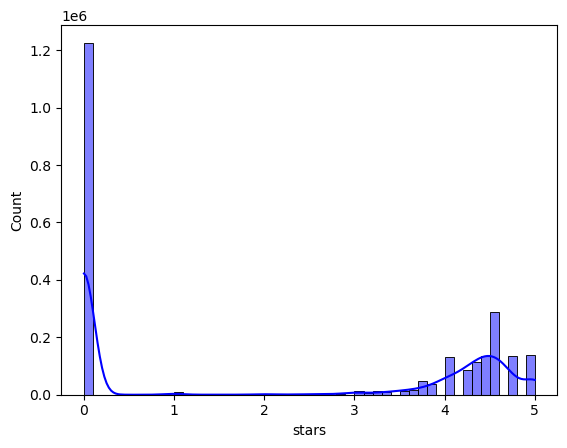

In [ ]:
# Visualizaciones (`stars`) - Histograma

sns.histplot(df['stars'], kde=True, bins=50, color="blue")

plt.show()

# La valoración 0 claramente es la más común
